In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sksurv.util import Surv
from sklearn.model_selection import train_test_split, cross_val_score, KFold, GridSearchCV
from sksurv.linear_model import CoxnetSurvivalAnalysis, CoxPHSurvivalAnalysis
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.base import clone
from sklearn.feature_selection import SelectKBest
from lifelines import KaplanMeierFitter
from lifelines.statistics import logrank_test

In [2]:
import warnings
warnings.filterwarnings('ignore', message='all coefficients are zero')

In [3]:
clinical = pd.read_parquet('../data/processed/clinical.parquet')
expression = pd.read_parquet('../data/processed/expression.parquet')

data = clinical.merge(
    expression,
    how='inner',
    left_on='patient_id',
    right_index=True,
    validate='one_to_one'
)

assert len(data) == 1978

In [4]:
numeric_cols = ['age_at_diagnosis', 'tumor_size', 'lymph_nodes_examined_positive', 'grade']
cat_cols = ['er_status', 'pr_status', 'her2_status', 'inferred_menopausal_state', 'oncotree_code']

In [5]:
X = data[numeric_cols + cat_cols]
y = Surv.from_arrays(event=data['event'], time=data['time'])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, random_state=42, test_size=0.2, stratify=data['event']
)

In [6]:
num_pipeline = Pipeline(
    [('imputer', SimpleImputer(strategy="median")), ('scaler', StandardScaler())]
)
cat_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')), ('encoder', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False))
])


ct = ColumnTransformer([
    ('num' , num_pipeline, numeric_cols), ('cat', cat_pipeline, cat_cols)
])

In [7]:
model_pipeline = Pipeline([('prep', ct) ,('cox', CoxPHSurvivalAnalysis())])
model_pipeline.fit(X_train, y_train)

c_index_test = model_pipeline.score(X_test, y_test)

print(f'Model A, test C-index: {c_index_test:.3f}')

Model A, test C-index: 0.688


In [8]:
kf = KFold(n_splits=5, shuffle=True, random_state=42)

a_cv_scores = []
for i, (train_index, test_index) in enumerate(kf.split(X_train)):
    fold_model = clone(model_pipeline)
    fold_model.fit(X_train.iloc[train_index], y_train[train_index])
    score = fold_model.score(X_train.iloc[test_index], y_train[test_index])
    a_cv_scores.append(score)
    print(f"Fold {i + 1}: C-index {score:.3f}")

print(f'Model A, CV C-index: {np.mean(a_cv_scores):.3f} ± {np.std(a_cv_scores):.3f}')


Fold 1: C-index 0.731
Fold 2: C-index 0.669
Fold 3: C-index 0.724
Fold 4: C-index 0.671
Fold 5: C-index 0.683
Model A, CV C-index: 0.695 ± 0.026


In [9]:
coefs = model_pipeline.named_steps['cox'].coef_
names = model_pipeline.named_steps['prep'].get_feature_names_out()

df = pd.DataFrame({
    'name' : names,
    'coef': coefs,
    'hazard_ratio': np.exp(coefs)
}).sort_values(by='hazard_ratio', ascending=False)

display(df)

,name,coef,hazard_ratio
6,cat__her2_status_Positive,0.403660,1.497294
7,cat__inferred_menopausal_state_Pre,0.335562,1.398726
2,num__lymph_nodes_examined_positive,0.269544,1.309368
0,num__age_at_diagnosis,0.211161,1.235111
1,num__tumor_size,0.182385,1.200076
3,num__grade,0.171268,1.186809
9,cat__oncotree_code_MDLC,-0.002721,0.997283
8,cat__oncotree_code_ILC,-0.024499,0.975799
5,cat__pr_status_Positive,-0.187824,0.828760
4,cat__er_status_Positive,-0.188305,0.828362


In [10]:
from lifelines import CoxPHFitter


ci_data = pd.DataFrame(model_pipeline.named_steps['prep'].transform(X_train), columns=names)

ci_data['time'] = y_train['time']
ci_data['event'] = y_train['event']

cox = CoxPHFitter()

cox.fit(ci_data, duration_col='time', event_col='event').print_summary()

<lifelines.CoxPHFitter: fitted with 1582 total observations, 1065 right-censored observations>
             duration col = 'time'
                event col = 'event'
      baseline estimation = breslow
   number of observations = 1582
number of events observed = 517
   partial log-likelihood = -3442.26
         time fit was run = 2026-11-19 23:45:35 UTC

---
                                    coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                                           
num__age_at_diagnosis               0.21      1.24      0.07            0.07            0.35                1.07                1.43
num__tumor_size                     0.18      1.20      0.03            0.12            0.24                1.13                1.27
num__lymph_nodes_examined_positive  0.27      1.31      0.03            0.22            0.32                1.24                1.38
num__grade                          0.17      1.19      0.05            0.06            0.28                1.07                1.32
cat__er_status_Positive            -0.19      0.83      0.13           -0.44            0.06                0.65                1.06
cat__pr_status_Positive            -0.19      0.83      0.11           -0.40            0.03                0.67                1.03
cat__her2_status_Positive           0.40      1.50      0.12            0.16            0.64                1.18                1.90
cat__inferred_menopausal_state_Pre  0.34      1.40      0.16            0.02            0.66                1.02                1.93
cat__oncotree_code_ILC             -0.02      0.98      0.18           -0.38            0.33                0.68                1.39
cat__oncotree_code_MDLC            -0.00      1.00      0.15           -0.30            0.30                0.74                1.34
cat__oncotree_code_Other           -0.81      0.44      0.32           -1.45           -0.18                0.24                0.83

                                    cmp to     z      p  -log2(p)
covariate                                                        
num__age_at_diagnosis                 0.00  2.88 <0.005      7.97
num__tumor_size                       0.00  6.14 <0.005     30.18
num__lymph_nodes_examined_positive    0.00 10.12 <0.005     77.50
num__grade                            0.00  3.16 <0.005      9.28
cat__er_status_Positive               0.00 -1.49   0.14      2.86
cat__pr_status_Positive               0.00 -1.72   0.09      3.53
cat__her2_status_Positive             0.00  3.31 <0.005     10.04
cat__inferred_menopausal_state_Pre    0.00  2.05   0.04      4.64
cat__oncotree_code_ILC                0.00 -0.14   0.89      0.16
cat__oncotree_code_MDLC               0.00 -0.02   0.99      0.02
cat__oncotree_code_Other              0.00 -2.52   0.01      6.41
---
Concordance = 0.71
Partial AIC = 6906.53
log-likelihood ratio test = 213.82 on 11 df
-log2(p) of ll-ratio test = 129.55

In [11]:
cox.check_assumptions(ci_data, p_value_threshold=0.05)

The ``p_value_threshold`` is set at 0.05. Even under the null hypothesis of no violations, some
covariates will be below the threshold by chance. This is compounded when there are many covariates.
Similarly, when there are lots of observations, even minor deviances from the proportional hazard
assumption will be flagged.

With that in mind, it's best to use a combination of statistical tests and visual tests to determine
the most serious violations. Produce visual plots using ``check_assumptions(..., show_plots=True)``
and looking for non-constant lines. See link [A] below for a full example.



<lifelines.StatisticalResult: proportional_hazard_test>
 null_distribution = chi squared
degrees_of_freedom = 1
             model = <lifelines.CoxPHFitter: fitted with 1582 total observations, 1065 right-censored observations>
         test_name = proportional_hazard_test

---
                                         test_statistic      p  -log2(p)
cat__er_status_Positive            km             30.35 <0.005     24.72
                                   rank           33.52 <0.005     27.08
cat__her2_status_Positive          km              2.25   0.13      2.91
                                   rank            3.16   0.08      3.73
cat__inferred_menopausal_state_Pre km              1.49   0.22      2.17
                                   rank            1.39   0.24      2.07
cat__oncotree_code_ILC             km              0.79   0.37      1.42
                                   rank            0.86   0.35      1.50
cat__oncotree_code_MDLC            km              0.95   0.33      1.60
                                   rank            0.47   0.50      1.01
cat__oncotree_code_Other           km              0.27   0.60      0.74
                                   rank            0.03   0.87      0.21
cat__pr_status_Positive            km              5.72   0.02      5.90
                                   rank            6.79   0.01      6.77
num__age_at_diagnosis              km              3.90   0.05      4.37
                                   rank            3.34   0.07      3.88
num__grade                         km              0.18   0.67      0.57
                                   rank            0.27   0.60      0.74
num__lymph_nodes_examined_positive km              0.16   0.69      0.54
                                   rank            0.32   0.57      0.80
num__tumor_size                    km              0.20   0.66      0.60
                                   rank            0.29   0.59      0.76



1. Variable 'num__age_at_diagnosis' failed the non-proportional test: p-value is 0.0482.

   Advice 1: the functional form of the variable 'num__age_at_diagnosis' might be incorrect. That
is, there may be non-linear terms missing. The proportional hazard test used is very sensitive to
incorrect functional forms. See documentation in link [D] below on how to specify a functional form.

   Advice 2: try binning the variable 'num__age_at_diagnosis' using pd.cut, and then specify it in
`strata=['num__age_at_diagnosis', ...]` in the call in `.fit`. See documentation in link [B] below.

   Advice 3: try adding an interaction term with your time variable. See documentation in link [C]
below.


2. Variable 'cat__er_status_Positive' failed the non-proportional test: p-value is <5e-05.

   Advice: with so few unique values (only 2), you can include `strata=['cat__er_status_Positive',
...]` in the call in `.fit`. See documentation in link [E] below.

3. Variable 'cat__pr_status_Positive' failed

[]

In [12]:
cox_strata = CoxPHFitter()

cox_strata.fit(ci_data, duration_col ='time', event_col='event', strata=['cat__er_status_Positive','cat__pr_status_Positive']).print_summary()

<lifelines.CoxPHFitter: fitted with 1582 total observations, 1065 right-censored observations>
             duration col = 'time'
                event col = 'event'
                   strata = ['cat__er_status_Positive', 'cat__pr_status_Positive']
      baseline estimation = breslow
   number of observations = 1582
number of events observed = 517
   partial log-likelihood = -2866.91
         time fit was run = 2026-11-19 23:45:35 UTC

---
                                    coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                                           
num__age_at_diagnosis               0.23      1.26      0.07            0.09            0.38                1.09                1.46
num__tumor_size                     0.18      1.19      0.03            0.12            0.23                1.13                1.26
num__lymph_nodes_examined_positive  0.26      1.30      0.03            0.21            0.31                1.23                1.37
num__grade                          0.19      1.21      0.05            0.08            0.29                1.08                1.34
cat__her2_status_Positive           0.37      1.45      0.12            0.13            0.61                1.14                1.84
cat__inferred_menopausal_state_Pre  0.36      1.43      0.16            0.04            0.68                1.04                1.97
cat__oncotree_code_ILC              0.01      1.01      0.18           -0.35            0.36                0.71                1.44
cat__oncotree_code_MDLC             0.00      1.00      0.15           -0.30            0.30                0.74                1.35
cat__oncotree_code_Other           -0.79      0.45      0.32           -1.43           -0.16                0.24                0.85

                                    cmp to     z      p  -log2(p)
covariate                                                        
num__age_at_diagnosis                 0.00  3.14 <0.005      9.22
num__tumor_size                       0.00  5.99 <0.005     28.82
num__lymph_nodes_examined_positive    0.00  9.68 <0.005     71.20
num__grade                            0.00  3.44 <0.005     10.73
cat__her2_status_Positive             0.00  2.99 <0.005      8.47
cat__inferred_menopausal_state_Pre    0.00  2.18   0.03      5.10
cat__oncotree_code_ILC                0.00  0.05   0.96      0.06
cat__oncotree_code_MDLC               0.00  0.00   1.00      0.00
cat__oncotree_code_Other              0.00 -2.46   0.01      6.18
---
Concordance = 0.68
Partial AIC = 5751.81
log-likelihood ratio test = 172.96 on 9 df
-log2(p) of ll-ratio test = 105.72

In [13]:
cox_strata.check_assumptions(ci_data, p_value_threshold=0.05, show_plots=False);

The ``p_value_threshold`` is set at 0.05. Even under the null hypothesis of no violations, some
covariates will be below the threshold by chance. This is compounded when there are many covariates.
Similarly, when there are lots of observations, even minor deviances from the proportional hazard
assumption will be flagged.

With that in mind, it's best to use a combination of statistical tests and visual tests to determine
the most serious violations. Produce visual plots using ``check_assumptions(..., show_plots=True)``
and looking for non-constant lines. See link [A] below for a full example.



<lifelines.StatisticalResult: proportional_hazard_test>
 null_distribution = chi squared
degrees_of_freedom = 1
             model = <lifelines.CoxPHFitter: fitted with 1582 total observations, 1065 right-censored observations>
         test_name = proportional_hazard_test

---
                                         test_statistic      p  -log2(p)
cat__her2_status_Positive          km              1.76   0.18      2.44
                                   rank            1.04   0.31      1.70
cat__inferred_menopausal_state_Pre km              1.55   0.21      2.23
                                   rank            1.64   0.20      2.32
cat__oncotree_code_ILC             km              0.60   0.44      1.18
                                   rank            0.91   0.34      1.56
cat__oncotree_code_MDLC            km              0.79   0.37      1.42
                                   rank            0.12   0.73      0.45
cat__oncotree_code_Other           km              0.09   0.77      0.38
                                   rank            0.31   0.58      0.79
num__age_at_diagnosis              km              3.97   0.05      4.43
                                   rank            8.24 <0.005      7.93
num__grade                         km              0.04   0.84      0.25
                                   rank            0.66   0.42      1.27
num__lymph_nodes_examined_positive km              0.13   0.71      0.49
                                   rank            1.02   0.31      1.68
num__tumor_size                    km              0.22   0.64      0.65
                                   rank            0.83   0.36      1.46



1. Variable 'num__age_at_diagnosis' failed the non-proportional test: p-value is 0.0041.

   Advice 1: the functional form of the variable 'num__age_at_diagnosis' might be incorrect. That
is, there may be non-linear terms missing. The proportional hazard test used is very sensitive to
incorrect functional forms. See documentation in link [D] below on how to specify a functional form.

   Advice 2: try binning the variable 'num__age_at_diagnosis' using pd.cut, and then specify it in
`strata=['num__age_at_diagnosis', ...]` in the call in `.fit`. See documentation in link [B] below.

   Advice 3: try adding an interaction term with your time variable. See documentation in link [C]
below.


---
[A]  https://lifelines.readthedocs.io/en/latest/jupyter_notebooks/Proportional%20hazard%20assumption.html
[B]  https://lifelines.readthedocs.io/en/latest/jupyter_notebooks/Proportional%20hazard%20assumption.html#Bin-variable-and-stratify-on-it
[C]  https://lifelines.readthedocs.io/en/latest/jupyte

In [14]:
hazards_ratio = cox.summary['exp(coef)']
stratified_hazards_ratio = cox_strata.summary['exp(coef)']

d = pd.concat([hazards_ratio, stratified_hazards_ratio], axis=1, keys=['unstratified', 'stratified'])
d = d.loc[~d.index.str.contains('er_status|pr_status', na=False)]
d['Δ%'] = ((d['stratified'] - d['unstratified']) / d['unstratified'] * 100).round(1)

assert (d['Δ%'].abs() < 5).all()

display(d)

,unstratified,stratified,Δ%
covariate,,,
num__age_at_diagnosis,1.235114,1.260297,2.0
num__tumor_size,1.200068,1.193646,-0.5
num__lymph_nodes_examined_positive,1.309393,1.295884,-1.0
num__grade,1.186815,1.206284,1.6
cat__her2_status_Positive,1.497308,1.445787,-3.4
cat__inferred_menopausal_state_Pre,1.398665,1.427347,2.1
cat__oncotree_code_ILC,0.975779,1.008736,3.4
cat__oncotree_code_MDLC,0.997252,1.000196,0.3
cat__oncotree_code_Other,0.443427,0.451705,1.9


- All hazard ratios change by less than 5% after stratifying by ER and PR, so model A's interpretation is robust

- Age shows a mild time-varying effect (Schoenfeld plot, p= 0.004 rank / 0.046 KM)

- the C-index comparison with model B uses the unstratified model

In [15]:
gene_cols = expression.columns.to_list()

X_b = data[gene_cols + numeric_cols + cat_cols]
y = Surv.from_arrays(event=data['event'], time=data['time'])

Xb_train, Xb_test, yb_train, yb_test = train_test_split(
    X_b, y, random_state=42, test_size=0.2, stratify=data['event']
)

assert Xb_test.index.equals(X_test.index)

In [16]:
def gene_variance(X, y):
    return np.var(X, axis=0)

In [17]:
genes_pipeline = Pipeline([('k_best', SelectKBest(score_func=gene_variance, k=1000)), ('scaler', StandardScaler())])

ct_b = ColumnTransformer([
    ('num' , num_pipeline, numeric_cols), 
    ('cat', cat_pipeline, cat_cols), 
    ('genes', genes_pipeline, gene_cols)
    ])

model_B_pipeline = Pipeline([('prep', ct_b) ,('cox', CoxnetSurvivalAnalysis(alpha_min_ratio=0.05, l1_ratio=0.9))])

model_B_pipeline.fit(Xb_train, yb_train);

In [18]:
alphas = model_B_pipeline.named_steps['cox'].alphas_
gs = GridSearchCV(model_B_pipeline, param_grid={'cox__alphas': [[a] for a in alphas[::5]]}, n_jobs=-1, cv=kf)

gs.fit(Xb_train, yb_train)

best_params = gs.best_params_
best_score = gs.best_score_

print(f"Model B - Best score: {best_score:.3f}")

Model B - Best score: 0.721


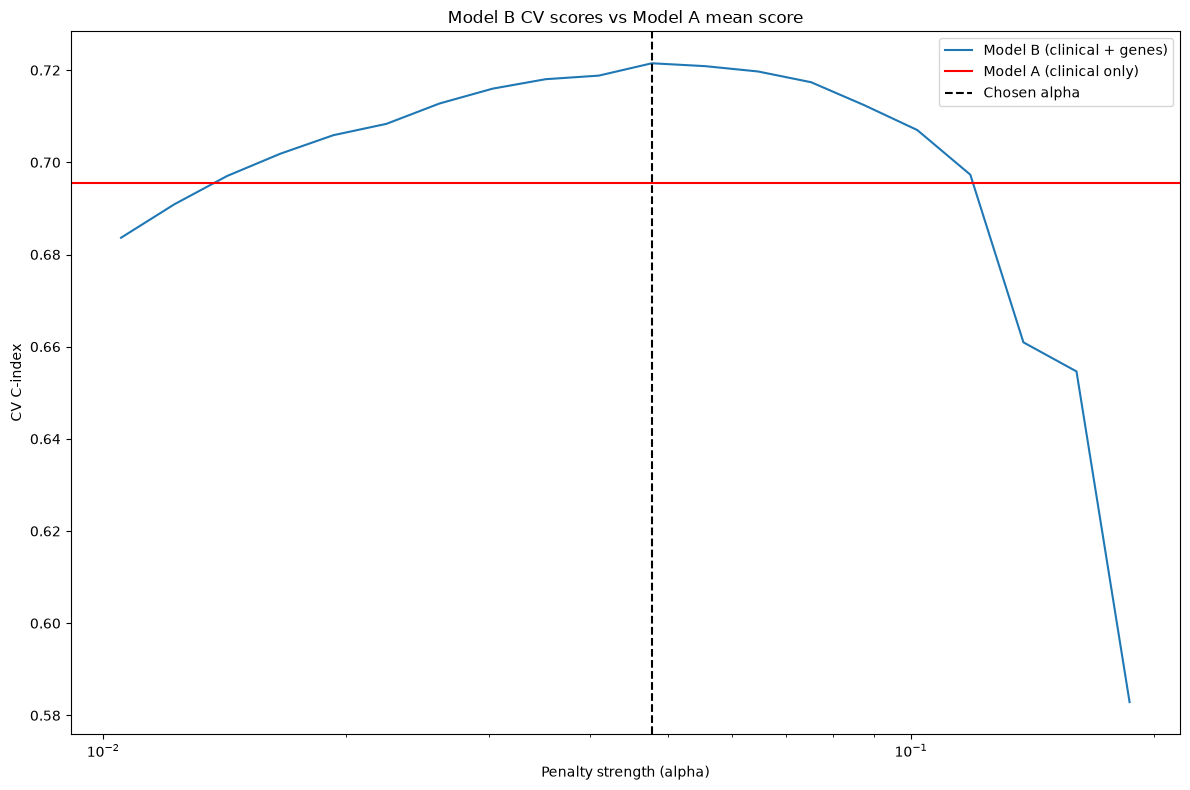

In [19]:
fig, ax = plt.subplots(figsize=(12,8))
b_cv_scores = gs.cv_results_['mean_test_score']

ax.plot(alphas[::5], b_cv_scores, label='Model B (clinical + genes)')

ax.set_xscale('log')

ax.axhline(np.mean(a_cv_scores), color='red', label='Model A (clinical only)')
ax.axvline(best_params['cox__alphas'][0], color='black',label='Chosen alpha', linestyle='--')

ax.set_title("Model B CV scores vs Model A mean score")
ax.set_xlabel("Penalty strength (alpha)")
ax.set_ylabel("CV C-index")

ax.legend()
plt.tight_layout()
fig.savefig('../reports/figures/model_b_alpha_tuning.png', dpi=150, bbox_inches='tight')
plt.show()

In [20]:
c_index_test_b = gs.score(Xb_test, yb_test)
print(f"Model B - test C-index: {c_index_test_b:.3f}")

Model B - test C-index: 0.733


In [21]:
b_coefs = gs.best_estimator_.named_steps['cox'].coef_.ravel()
b_names = gs.best_estimator_.named_steps['prep'].get_feature_names_out()

modelB_df = pd.DataFrame({
    'name' : b_names,
    'coef': b_coefs,
    'hazard_ratio': np.exp(b_coefs)
}).sort_values(by='hazard_ratio', ascending=False)

kept = modelB_df[modelB_df['coef'] != 0]
print(len(kept))

22


In [22]:
num_names = kept[kept['name'].str.contains("num_")]
gene_names = kept[kept['name'].str.contains("genes_")]

print(len(num_names), len(gene_names))

2 20


In [23]:
top_10_kept = kept.sort_values(by='coef',key=abs, ascending=False).head(10)

model_a_mean = np.mean(a_cv_scores)

display(top_10_kept)

models_df = pd.DataFrame({
    'CV C-index' : [model_a_mean, gs.best_score_],
    'Test C-index': [c_index_test, c_index_test_b],
 
}, index=['Model_A (clinical)', 'Model_B (clinical + genes)'])
display(models_df.round(3))

,name,coef,hazard_ratio
2,num__lymph_nodes_examined_positive,0.239194,1.270225
1,num__tumor_size,0.134702,1.144196
165,genes__CDCA5,0.131185,1.140179
940,genes__TMEM101,-0.055082,0.946408
91,genes__BRINP3,0.051548,1.052899
802,genes__S100P,0.047223,1.048356
902,genes__SUSD3,-0.041354,0.959490
922,genes__TENT5C,-0.035294,0.965322
281,genes__DDIT4,0.026082,1.026425
699,genes__PLAC9P1,-0.022372,0.977876


,CV C-index,Test C-index
Model_A (clinical),0.695,0.688
Model_B (clinical + genes),0.721,0.733


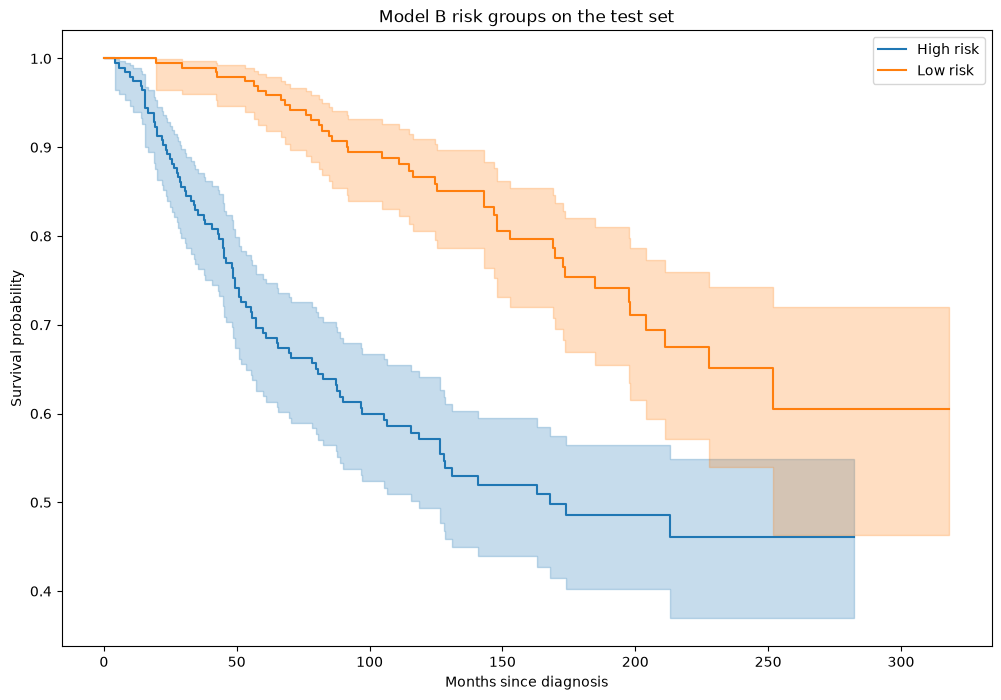

In [24]:
risk_scores = gs.predict(Xb_test)
median_mask = risk_scores > np.median(risk_scores)

kmf_high_fitter = KaplanMeierFitter()
kmf_low_fitter = KaplanMeierFitter()

kmf_high = kmf_high_fitter.fit(yb_test['time'][median_mask], yb_test['event'][median_mask], label='High risk')
kmf_low = kmf_low_fitter.fit(yb_test['time'][~median_mask], yb_test['event'][~median_mask], label='Low risk')

fig, ax = plt.subplots(figsize=(12,8))

kmf_high.plot(ax=ax)
kmf_low.plot(ax=ax)

ax.set_title('Model B risk groups on the test set')
ax.set_xlabel('Months since diagnosis')
ax.set_ylabel('Survival probability')
fig.savefig('../reports/figures/km_risk_groups_model_b.png', dpi=150, bbox_inches='tight')
plt.show()

In [25]:
result = logrank_test(yb_test['time'][median_mask], yb_test['time'][~median_mask], event_observed_A=yb_test['event'][median_mask], event_observed_B=yb_test['event'][~median_mask])

print(f'Log-rank p-value: {result.p_value:.2e}')
print(kmf_high.survival_function_at_times(120))
print(kmf_low.survival_function_at_times(120))

Log-rank p-value: 3.20e-09
120    0.571042
Name: High risk, dtype: float64
120    0.866431
Name: Low risk, dtype: float64


## Summary

**Model comparison (same test patients for both models):**

| Model | CV C-index (5-fold) | Test C-index |
|---|---|---|
| A: clinical only | 0.695 | 0.688 |
| B: clinical + genes | 0.721 | 0.733 |

- **Gene expression improves the prediction:** +0.03 in cross-validation and +0.05 on the test set.

**Model A (Cox, clinical):**
- Lymph nodes, tumour size, grade, age and HER2 status are the strongest risk factors; histology "Other" is protective.
- ER and PR violate the proportional hazards assumption. In a model stratified by ER and PR, all other hazard ratios changed by less than 5%, so the interpretation is robust.
- Age shows a mild time-varying effect (Schoenfeld residuals).

**Model B (penalised Cox, clinical + 1,000 most variable genes):**
- The penalty strength was tuned with 5-fold cross-validation; too strong a penalty underfits, too weak a penalty overfits.
- The model keeps 22 of 1,011 features: 20 genes plus lymph nodes and tumour size.
- The strongest genes are consistent with known biology: CDCA5 (cell division, higher risk) likely replaces grade, and SUSD3 (linked to the estrogen receptor, lower risk) likely replaces ER status.

**Risk groups (test set, split at the median of model B's risk score):**
- 10-year survival: 87% in the low-risk group vs 57% in the high-risk group (log-rank p = 3.2e-09).
